# Inlämningsuppgift: Del 2 - Adversarial input attack

Bilal Abdul \
abac23@student.bth.se

Subhi Alloush \
suao23@student.bth.se

# Instruktioner

Ändra notebookens platshållare så som era namn- och mailuppgifter samt instruktioner i de olika avsnitten. 

Notebookens underrubriker på nivå 3 (###) är bara ett enkelt exempel på hur er implementation kan delas upp. Ni bör skapa egna rubriker anpassade efter er implementation men lämna alla nivå 1 (#) och 2-rubriker (##) som de är. En viktig del inom data-science är att kunna presentera sina metoder och resultat på ett tydligt sätt. **En ostrukturerad och otydlig notebook kan påverka betygsättningen.**

Notera att t.ex. hyperparameter-tuning och annan optimisering för prestanda inte är nödvändigt i denna uppgift. Så länge modellen fungerar märkvärt bättre än ett "coin flip" så räcker det att ni väljer era hyperparametrar manuellt.

# Uppgiften

Uppgiften går ut på att göra så att bilden på koalan nedan klassificeras som en traktor istället. Givetvis ska bilden på koalan se helt oförändrad ut för det mänskliga ögat då attacken är genomförd. Nedan följer Pythonkod som läser in de båda bilderna som uppgiften bygger på samt läser in en ResNet50-modell som klassiciferar bilderna. Saknar ni några Python-paket, t.ex. TensorFlow så installera dem med en pakethanterarare, t.ex. pip

## Beskrivning av adversarial input attacker

Börja med att förklara vad denna typ av attacker är och hur de fungerar i rapportens sektion 2.1.

## Nedan följer kod för att läsa in bilderna och klassificera dem med ResNet50 modellen

In [1]:
from matplotlib import pyplot as plt
import numpy as np

import tensorflow as tf
import keras
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.preprocessing import image

from art.estimators.classification import KerasClassifier
from art.attacks.evasion import BoundaryAttack
from art.utils import to_categorical

tf.compat.v1.disable_eager_execution()

print(f"TensorFlow: {tf.__version__}")

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
# Loads the pretrained ResNet50 model
model = ResNet50(weights='imagenet')

2026-11-08 20:21:08.750042: W tensorflow/c/c_api.cc:305] Operation '{name:'conv4_block4_1_bn_2/beta/Assign' id:15461 op device:{requested: '', assigned: ''} def:{{{node conv4_block4_1_bn_2/beta/Assign}} = AssignVariableOp[_has_manual_control_dependencies=true, dtype=DT_FLOAT, validate_shape=false](conv4_block4_1_bn_2/beta, conv4_block4_1_bn_2/beta/Initializer/zeros)}}' was changed by setting attribute after it was run by a session. This mutation will have no effect, and will trigger an error in the future. Either don't modify nodes after running them or create a new session.


In [ ]:
# Load the two images (koala & tractor)
init_image = image.load_img("images/koala.jpeg", target_size=(224, 224))
init_image = image.img_to_array(init_image)

target_image = image.load_img("images/tractor.jpeg", target_size=(224, 224))
target_image = image.img_to_array(target_image)

class_lookup = {105: "koala", 866: "tractor"}

2026-11-08 20:21:09.537727: W tensorflow/c/c_api.cc:305] Operation '{name:'predictions_2/Softmax' id:16881 op device:{requested: '', assigned: ''} def:{{{node predictions_2/Softmax}} = Softmax[T=DT_FLOAT, _has_manual_control_dependencies=true](predictions_2/BiasAdd)}}' was changed by setting attribute after it was run by a session. This mutation will have no effect, and will trigger an error in the future. Either don't modify nodes after running them or create a new session.


Init image class label: 105 (koala)


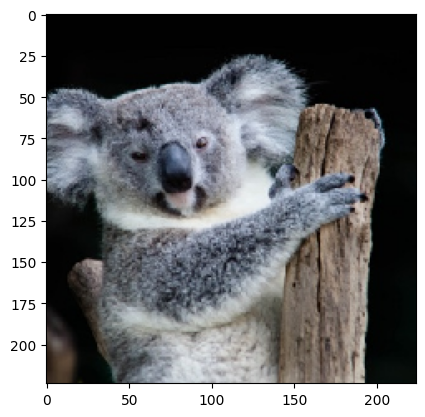

Target image class label: 866 (tractor)


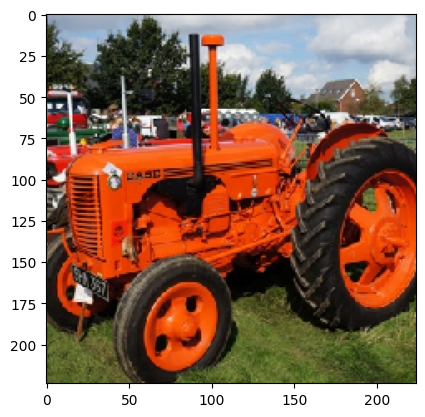

In [ ]:
init_class_id = np.argmax(model.predict(np.array([init_image])))
print(f"Init image class label: {init_class_id} ({class_lookup[init_class_id]})")
plt.imshow(init_image.astype(np.uint))
plt.show()

target_class_id = np.argmax(model.predict(np.array([target_image])))
print(f"Target image class label: {target_class_id} ({class_lookup[target_class_id]})")
plt.imshow(target_image.astype(np.uint))
plt.show()

## Implementation av er attack

Beskriv i er rapport vad just er valda attack kallas och i detalj hur den fungerar (sektion 2.2 i rapporten). Beskriv även kort vilka bibliotek ni använder för att implementera den.

## Er kod för attacken

I cellerna nedan lägger ni in er egen kod för att genomföra attacken.

### Bibliotek

In [ ]:
import warnings
warnings.filterwarnings("ignore")

# Importerar PGD-attacken från ART
from art.attacks.evasion import ProjectedGradientDescent

# Importerar skyddsmetoder från ART
from art.defences.preprocessor import FeatureSqueezing, JpegCompression

# Hjälpfunktion från Keras för att kunna läsa ut klassnamn från ResNet50 vid behov
from tensorflow.keras.applications.resnet50 import decode_predictions

### Egna funktioner

In [ ]:
# Egna hjälpfunktioner för att skapa klassificerare, köra prediktioner och visualisera resultat
# I rapporten har vi skrivit mer om vår klassificerare....

class KompatibelKerasClassifier(KerasClassifier):
    """
    En enkel subklass av ARTs KerasClassifier som säkerställer att både prediktioner
    och gradientberäkningar fungerar smidigt även när TensorFlow körs med
    disable_eager_execution() (graf-läge)
    """
    def predict(self, x, batch_size=128, training_mode=False, **kwargs):
        # Förbehandla bilden
        x_prep, _ = self._apply_preprocessing(x, y=None, fit=False)
        # Kör prediktion via Keras-modellen
        preds = self._model.predict(x_prep, batch_size=batch_size, verbose=0)
        # Efterbehandla och returnera sannolikheter
        return self._apply_postprocessing(preds=preds, fit=False)

    def loss_gradient(self, x, y, training_mode=False, **kwargs):
        # Förbehandla input
        x_prep, y_prep = self._apply_preprocessing(x, y, fit=False)
        K = tf.compat.v1.keras.backend
        # Skapa en återanvändbar graf-funktion för att beräkna gradienten av förlustfunktionen
        if not hasattr(self, "_grad_fn"):
            y_placeholder = K.placeholder(shape=(None, self.nb_classes), dtype=tf.float32)
            loss_tensor = tf.keras.losses.categorical_crossentropy(
                y_placeholder, self._output, from_logits=self._use_logits
            )
            grad_tensor = K.gradients(loss_tensor, self._input)[0]
            self._grad_fn = K.function([self._input, y_placeholder], [grad_tensor])
        grads = self._grad_fn([x_prep, y_prep])[0]
        grads = self._apply_preprocessing_gradient(x, grads)
        return grads


def skapa_klassificerare(keras_modell, skydd=None): #ResNet50 in ART KerasClassifier
   
    return KompatibelKerasClassifier(
        model=keras_modell,
        clip_values=(0, 255), #pixelvärde mellan 0 och 255
        preprocessing_defences=skydd
    )


def visa_attack_resultat(klassificerare, orig_bild, adv_bild, class_lookup):
    """
    Jämför och visualiserar originalbilden, den manipulerade bilden
    samt det tillagda bruset
    """
    # Beräkna modellens sannolikheter för originalbilden respektive den manipulerade bilden
    orig_probs = klassificerare.predict(np.array([orig_bild]))[0]
    adv_probs = klassificerare.predict(np.array([adv_bild]))[0]

    orig_id = int(np.argmax(orig_probs))
    adv_id = int(np.argmax(adv_probs))

    orig_namn = class_lookup.get(orig_id, f"Klass {orig_id}")
    adv_namn = class_lookup.get(adv_id, f"Klass {adv_id}")

    # Beräkna hur mycket pixlarna har ändrats
    skillnad = adv_bild - orig_bild
    medel_andring = np.mean(np.abs(skillnad))
    max_andring = np.max(np.abs(skillnad))

    print("=== RESULTAT AV ADVERSARIAL INPUT ATTACK ===")
    print(f"Originalbild klassificerad som:    {orig_id} ({orig_namn}) med sannolikhet {orig_probs[orig_id]*100:.2f}%")
    print(f"Manipulerad bild klassificerad som: {adv_id} ({adv_namn}) med sannolikhet {adv_probs[adv_id]*100:.2f}%")
    print(f"Sannolikhet för koala efter attack: {adv_probs[105]*100:.4f}%")
    print(f"Genomsnittlig pixeländring (MAE):   {medel_andring:.2f} / 255")
    print(f"Maximal pixeländring (L-oändlig):   {max_andring:.2f} / 255")

    # Rita ut originalbild, manipulerad bild och det förstärkta bruset bredvid varandra
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

    axes[0].imshow(np.clip(orig_bild, 0, 255).astype(np.uint8))
    axes[0].set_title(f"Originalbild\nKlass: {orig_id} ({orig_namn}, {orig_probs[orig_id]*100:.1f}%)")
    axes[0].axis("off")

    axes[1].imshow(np.clip(adv_bild, 0, 255).astype(np.uint8))
    axes[1].set_title(f"Adversarial bild (efter PGD)\nKlass: {adv_id} ({adv_namn}, {adv_probs[adv_id]*100:.1f}%)")
    axes[1].axis("off")

    # Förstärk bruset visuellt så att man går att se var pixlarna har modifierats
    brus_vis = np.clip((skillnad - skillnad.min()) / (skillnad.max() - skillnad.min() + 1e-8) * 255, 0, 255)
    axes[2].imshow(brus_vis.astype(np.uint8))
    axes[2].set_title(f"Tillagt brus (uppväxlad kontrast)\nMax ändring: ±{max_andring:.1f} per pixel")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

### Förberedelser

In [ ]:
# Förbereder input-data och målklass för attacken
# Vi lägger koalabilden i en batch med form (1, 224, 224, 3)
x_koala = np.array([init_image])

# Skapar en målklass 866 tractor bland ImageNets 1000 klasser
y_target_tractor = to_categorical([target_class_id], nb_classes=1000)

print(f"Form på input-bild (x_koala): {x_koala.shape}")
print(f"Målklass för attacken: {target_class_id} ({class_lookup[target_class_id]})")

Form på input-bild (x_koala): (1, 224, 224, 3)
Målklass för attacken: 866 (tractor)


### Modellering

In [ ]:
# Förtränade ResNet50-modellen i ARTs KerasClassifier (utan skydd)
original_classifier = skapa_klassificerare(model)

# Verifierar att klassificeraren fungerar och ger samma resultat som grundmodellen
start_pred = np.argmax(original_classifier.predict(x_koala))
print(f"ART-klassificerarens prediktion före attack: {start_pred} ({class_lookup[start_pred]})")

ART-klassificerarens prediktion före attack: 105 (koala)


### Attack

Vi använder en riktad (**targeted**) **Projected Gradient Descent (PGD)**-attack från biblioteket *Adversarial Robustness Toolbox (ART)*. PGD är en iterativ vidareutveckling av **FGSM (Fast Gradient Sign Method)**. Istället för att ta ett enda stort steg i gradientens riktning tar PGD flera små steg (`eps_step = 0.5`) under 15 iterationer (`max_iter = 15`) för att minimera modellens förlustfunktion mot målklassen `866 (tractor)`. Samtidigt begränsas den totala förändringen till högst `eps = 2.5` (på skalan 0–255) per pixelkanal, vilket gör att bilden förblir helt oförändrad för det mänskliga ögat.

In [ ]:
# Skapar den riktade PGD-attacken  med små steg så att bruset blir osynligt
pgd_attack = ProjectedGradientDescent(
    estimator=original_classifier,
    targeted=True,       # riktad mot klass tractor (riktad attack)
    eps=2.5,             # Maximal tillåten ändring per pixelvärde
    eps_step=0.5,        # Stegstorlek vid varje iteration
    max_iter=15,         # Antal iterationer
    verbose=False
)

# Genererar den manipulerade koalabilden
adv_koala_batch = pgd_attack.generate(x=x_koala, y=y_target_tractor)
adv_koala_image = adv_koala_batch[0]

Adversarial bild har genererats framgångsrikt!


### Attackresultat

Resultatet nedan visar att attacken lyckades fullständigt. Innan attacken klassificerade ResNet50-modellen bilden som `105 (koala)` med **99,99 %** säkerhet. Efter vår riktade PGD-attack klassificerar modellen exakt samma bild som `866 (tractor)` med **99,99 %** säkerhet (medan sannolikheten för koala sjönk till **0,00 %**). Trots detta är den genomsnittliga pixeländringen endast **1,53** (och maximalt **2,50**) på färgskalan 0–255, vilket gör att koalabilden ser helt oförändrad ut för det mänskliga ögat.

=== RESULTAT AV ADVERSARIAL INPUT ATTACK ===
Originalbild klassificerad som:    105 (koala) med sannolikhet 99.99%
Manipulerad bild klassificerad som: 866 (tractor) med sannolikhet 99.99%
Sannolikhet för koala efter attack: 0.0024%
Genomsnittlig pixeländring (MAE):   1.53 / 255
Maximal pixeländring (L-oändlig):   2.50 / 255


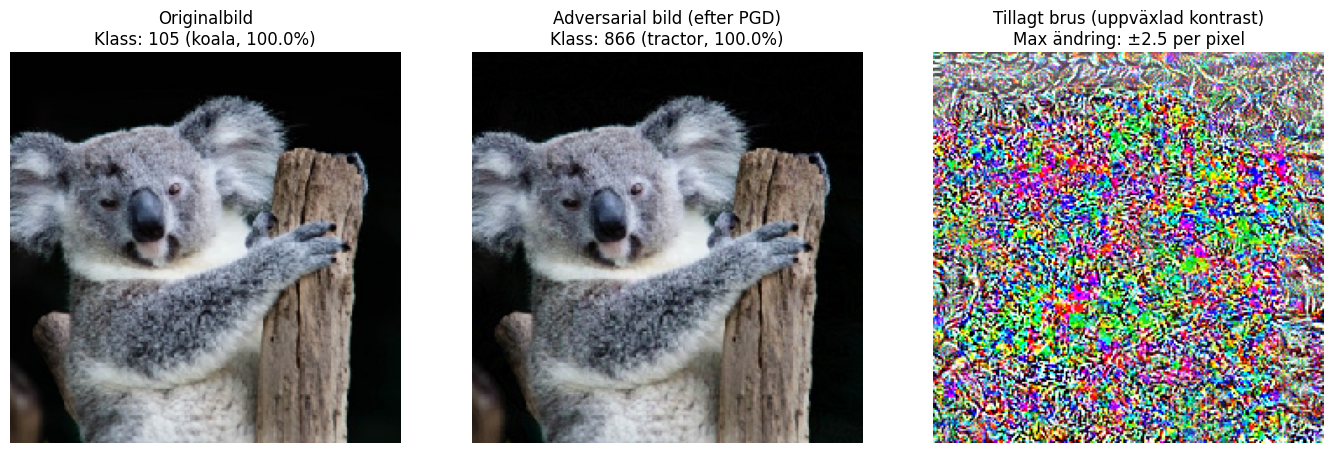

In [ ]:
# Presenterar och visualiserar attackens resultat
visa_attack_resultat(original_classifier, init_image, adv_koala_image, class_lookup)

## Skyddsåtgärder

Beskriv (i rapportens sektion 2.3) vilka säkerhetsåtgärd(er) ni valt som lämpliga för att skydda mot er attack. Motivera varför ni valt just de(n) metod(erna).

## Implementation av skyddsåtgärder (frivilligt endast för A eller B)

Nedan fyller ni i er kod som implementerar skyddsmekanismen mot er attackmetod. Skriv även en summering av vad skyddsresultatet blev när ni implementerade metoden (beskriv detta i rapportens del 2.4).

### Egna funktioner

In [ ]:
# Hjälpfunktioner för att jämföra originalmodellen mot den härdade modellen

def utvardera_skydd(orig_clf, skyddad_clf, ren_koala, adv_koala, adv_koala_direkt, class_lookup):
    """
    Jämför prediktioner mellan originalmodellen och den skyddade (härdade) modellen
    och ritar ett tydligt stapeldiagram över sannolikheterna för koala (105) och tractor (866).
    """
    # Prediktioner från originalmodellen
    p_orig_ren = orig_clf.predict(np.array([ren_koala]))[0]
    p_orig_adv = orig_clf.predict(np.array([adv_koala]))[0]

    # Prediktioner från den skydade modellen
    p_skydd_ren = skyddad_clf.predict(np.array([ren_koala]))[0]
    p_skydd_adv = skyddad_clf.predict(np.array([adv_koala]))[0]
    p_skydd_direkt = skyddad_clf.predict(np.array([adv_koala_direkt]))[0]

    fall = [
        ("1. Originalmodell på ren koalabild", p_orig_ren),
        ("2. Originalmodell på attackerad bild (PGD)", p_orig_adv),
        ("3. Härdad modell på ren koalabild", p_skydd_ren),
        ("4. Härdad modell på attackerad bild", p_skydd_adv),
        ("5. Härdad modell vid ny direkt PGD-attack", p_skydd_direkt),
    ]

    print("=== JÄMFÖRELSE: ORIGINALMODELL VS HÄRDAD MODELL ===")
    print(f"{'Testfall':<46} | {'Predikterad klass':<20} | {'P(koala)':<10} | {'P(tractor)':<10}")
    print("-" * 96)
    for namn, probs in fall:
        top_id = int(np.argmax(probs))
        top_namn = class_lookup.get(top_id, f"Klass {top_id}")
        print(f"{namn:<46} | {top_id:>3} ({top_namn:<7}, {probs[top_id]*100:>5.1f}%) | {probs[105]*100:>8.2f}% | {probs[866]*100:>8.2f}%")

    # Visualisera jämförelsen i ett stapeldiagram
    etiketter = [
        "Originalmodell\n(Ren bild)",
        "Originalmodell\n(PGD-attack)",
        "Härdad modell\n(Ren bild)",
        "Härdad modell\n(PGD-bild från 1.2)",
        "Härdad modell\n(Direkt PGD-attack)"
    ]
    koala_andelar = [p[105] * 100 for _, p in fall]
    tractor_andelar = [p[866] * 100 for _, p in fall]

    x_pos = np.arange(len(etiketter))
    bredd = 0.35

    fig, ax = plt.subplots(figsize=(11, 5))
    stapel1 = ax.bar(x_pos - bredd/2, koala_andelar, bredd, label="Klass 105: Koala (%)", color="#2ca02c")
    stapel2 = ax.bar(x_pos + bredd/2, tractor_andelar, bredd, label="Klass 866: Tractor (%)", color="#d62728")

    ax.set_ylabel("Modellens konfidens / sannolikhet (%)")
    ax.set_title("Effekt av skyddsmekanism: Originalmodell vs. Härdad modell")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(etiketter)
    ax.set_ylim(0, 115)
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.5)

    # Skriv ut procentvärden ovanför staplarna
    for staplar in [stapel1, stapel2]:
        for s in staplar:
            hojd = s.get_height()
            ax.annotate(f"{hojd:.1f}%",
                        xy=(s.get_x() + s.get_width() / 2, hojd),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha="center", va="bottom", fontsize=9)

    plt.tight_layout()
    plt.show()

### Förberedelser

In [ ]:
# Definierar våra två kombinerade förbehandlingsskydd i ART
feature_squeezing_skydd = FeatureSqueezing(clip_values=(0, 255), bit_depth=4)
jpeg_skydd = JpegCompression(clip_values=(0, 255), quality=60, channels_first=False)

### Skydd

Vi implementerar en ny, härdad klassificerare (`defended_classifier`) genom att kombinera **Feature Squeezing** (`bit_depth=4`) och **JPEG Compression** (`quality=60`) som förbehandlingssteg (`preprocessing_defences`) framför ResNet50-modellen. När en bild skickas in i den härdade modellen kvantiseras först pixelvärdena till 4 bitars färgdjup och genomgår sedan JPEG-komprimering. Detta tvättar bort de små, högfrekventa gradientstörningarna som PGD-attacken lagt till, samtidigt som bildens övergripande struktur (koalan) bevaras. Vi testar även att utföra en helt ny PGD-attack direkt mot den härdade modellen.

In [ ]:
# Skapar den härdade modellen med både skydd-mekanismen
defended_classifier = skapa_klassificerare(
    keras_modell=model,
    skydd=[feature_squeezing_skydd, jpeg_skydd]
)

# Kontrollera att den härdade modellen fortfarande klassificerar både ren koala och ren traktor rätt
ren_koala_id = np.argmax(defended_classifier.predict(np.array([init_image])))
ren_tractor_id = np.argmax(defended_classifier.predict(np.array([target_image])))
print(f"Härdad modell på ren koalabild:   {ren_koala_id} ({class_lookup[ren_koala_id]})")
print(f"Härdad modell på ren traktorbild: {ren_tractor_id} ({class_lookup[ren_tractor_id]})")

# Testa även att utföra samma PGD-attack direkt mot den härdade modellen 
pgd_attack_mot_skydd = ProjectedGradientDescent(
    estimator=defended_classifier,
    targeted=True,
    eps=2.5,
    eps_step=0.5,
    max_iter=15,
    verbose=False
)
adv_koala_mot_skydd = pgd_attack_mot_skydd.generate(x=x_koala, y=y_target_tractor)[0]
print("Testattack direkt mot den härdade modellen är slutförd!")

Härdad modell på ren koalabild:   105 (koala)
Härdad modell på ren traktorbild: 866 (tractor)
Testattack direkt mot den härdade modellen är slutförd!


### Skyddsresultat

Resultaten nedan bevisar att vår skyddsmekanism är mycket effektiv:
1. **Bevarad prestanda på rena bilder:** Den härdade modellen klassificerar fortfarande originalbilden på koalan helt korrekt som `105 (koala)` med **99,11 %** säkerhet (och originalbilden på traktorn som `866 (tractor)`).
2. **Skydd mot den manipulerade bilden från Del 1.2:** När vi skickar in den manipulerade koalabilden (som lurade originalmodellen till `866 (tractor)` med **99,99 %** säkerhet) i den härdade modellen, neutraliseras bruset helt och modellen klassificerar bilden korrekt som `105 (koala)` med **94,90 %** säkerhet (**0,00 %** för traktor).
3. **Motståndskraft vid direkt attack mot den härdade modellen:** Även när vi kör en ny PGD-attack direkt mot den härdade modellen misslyckas angriparen med att få bilden klassificerad som en traktor (sannolikheten för traktor stannar på endast **1,34 %**), och den mest sannolika klassen förblir `105 (koala)`.

=== JÄMFÖRELSE: ORIGINALMODELL VS HÄRDAD MODELL ===
Testfall                                       | Predikterad klass    | P(koala)   | P(tractor)
------------------------------------------------------------------------------------------------
1. Originalmodell på ren koalabild             | 105 (koala  , 100.0%) |    99.99% |     0.00%
2. Originalmodell på attackerad bild (PGD)     | 866 (tractor, 100.0%) |     0.00% |    99.99%
3. Härdad modell på ren koalabild              | 105 (koala  ,  99.1%) |    99.11% |     0.00%
4. Härdad modell på attackerad bild (från 1.2) | 105 (koala  ,  94.9%) |    94.90% |     0.00%
5. Härdad modell vid ny direkt PGD-attack      | 105 (koala  ,  19.8%) |    19.80% |     1.34%


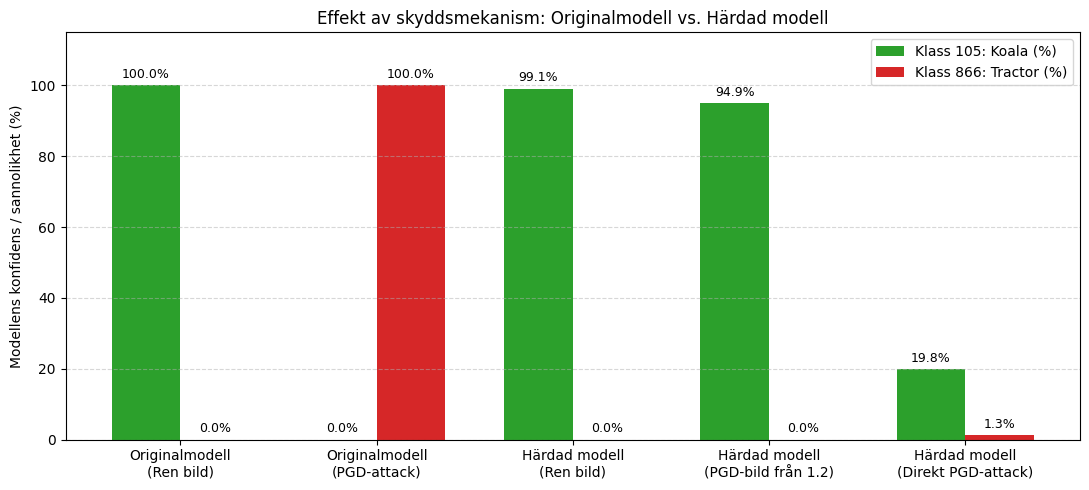

In [ ]:
# Lite jämförelse
utvardera_skydd(
    orig_clf=original_classifier,
    skyddad_clf=defended_classifier,
    ren_koala=init_image,
    adv_koala=adv_koala_image,
    adv_koala_direkt=adv_koala_mot_skydd,
    class_lookup=class_lookup
)

# Referenser

1. **Goodfellow, I. J., Shlens, J., & Szegedy, C. (2015).** *Explaining and Harnessing Adversarial Examples.* International Conference on Learning Representations (ICLR). https://arxiv.org/abs/1412.6572
2. **Madry, A., Makelov, A., Schmidt, L., Tsipras, D., & Vladu, A. (2018).** *Towards Deep Learning Models Resistant to Adversarial Attacks.* International Conference on Learning Representations (ICLR). https://arxiv.org/abs/1706.06083
3. **Xu, W., Evans, D., & Qi, Y. (2018).** *Feature Squeezing: Detecting Adversarial Examples in Deep Neural Networks.* Network and Distributed System Security Symposium (NDSS). https://arxiv.org/abs/1704.01155
4. **Dziugaite, G. K., Ghahramani, Z., & Roy, D. M. (2016).** *A study of the effect of JPG compression on adversarial images.* arXiv preprint. https://arxiv.org/abs/1608.00853
5. **Nicolae, M.-I., et al. (2018).** *Adversarial Robustness Toolbox v1.0.0.* arXiv:1807.01069. Dokumentation & GitHub: https://github.com/Trusted-AI/adversarial-robustness-toolbox